# Dataset Cleaning for Player Teams

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore
from scipy.stats import iqr

player_teams = pd.read_csv("../basketballPlayoffs/players_teams.csv")
player_teams.head()



player_teamsy11 = pd.read_csv("../basketballPlayoffs/Season_11/players_teams.csv")
merged_player_teams = pd.concat([player_teams, player_teamsy11], ignore_index=True)

merged_player_teams.to_csv("../basketballPlayoffs/y11_player_teams.csv", index=False)

player_teams = pd.read_csv("../basketballPlayoffs/y11_player_teams.csv")




# Check For Null Values

In [5]:
null = player_teams.isnull().values.any()
nan = player_teams.isna().values.any()

print(null)
print(nan)

# No Missing Values detected so no need of cleaning

True
True


# Dropping Unique Value Columns

In [6]:
for name in player_teams:
    for col in player_teams.columns:
        if len(player_teams[col].unique()) == 1:
            player_teams.drop(col, inplace=True, axis=1)
    print(f"Processed {name}: Remaining columns: {player_teams.columns}")


Processed playerID: Remaining columns: Index(['playerID', 'year', 'stint', 'tmID', 'GP', 'GS', 'minutes', 'points',
       'oRebounds', 'dRebounds', 'rebounds', 'assists', 'steals', 'blocks',
       'turnovers', 'PF', 'fgAttempted', 'fgMade', 'ftAttempted', 'ftMade',
       'threeAttempted', 'threeMade', 'dq', 'PostGP', 'PostGS', 'PostMinutes',
       'PostPoints', 'PostoRebounds', 'PostdRebounds', 'PostRebounds',
       'PostAssists', 'PostSteals', 'PostBlocks', 'PostTurnovers', 'PostPF',
       'PostfgAttempted', 'PostfgMade', 'PostftAttempted', 'PostftMade',
       'PostthreeAttempted', 'PostthreeMade', 'PostDQ'],
      dtype='object')
Processed year: Remaining columns: Index(['playerID', 'year', 'stint', 'tmID', 'GP', 'GS', 'minutes', 'points',
       'oRebounds', 'dRebounds', 'rebounds', 'assists', 'steals', 'blocks',
       'turnovers', 'PF', 'fgAttempted', 'fgMade', 'ftAttempted', 'ftMade',
       'threeAttempted', 'threeMade', 'dq', 'PostGP', 'PostGS', 'PostMinutes',
       'Po

# Dealing with Redundancy

In [7]:

row_count = player_teams.shape[0]
player_teams.drop_duplicates(inplace=True)
afterDups_count = player_teams.shape[0]
rows_deleted = row_count - afterDups_count
print(f"Number of rows deleted: {rows_deleted}")


Number of rows deleted: 0


# Dealing With Outliers

# Z-Score Implementation

/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3768/3042557006.py:12: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3768/3042557006.py:12: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3768/3042557006.py:12: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3768/3042557006.py:12: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to

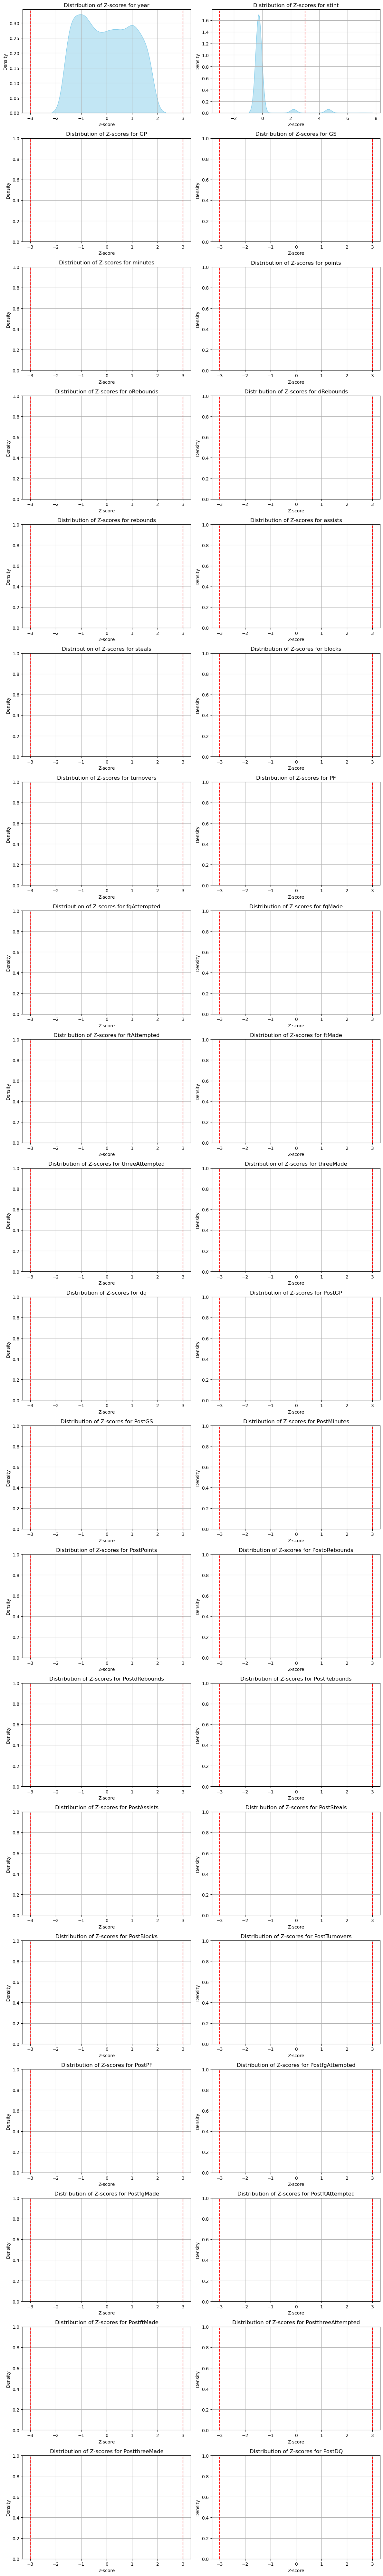

Number of outliers per column:
year                   0
stint                 71
GP                     0
GS                     0
minutes                0
points                 0
oRebounds              0
dRebounds              0
rebounds               0
assists                0
steals                 0
blocks                 0
turnovers              0
PF                     0
fgAttempted            0
fgMade                 0
ftAttempted            0
ftMade                 0
threeAttempted         0
threeMade              0
dq                     0
PostGP                 0
PostGS                 0
PostMinutes            0
PostPoints             0
PostoRebounds          0
PostdRebounds          0
PostRebounds           0
PostAssists            0
PostSteals             0
PostBlocks             0
PostTurnovers          0
PostPF                 0
PostfgAttempted        0
PostfgMade             0
PostftAttempted        0
PostftMade             0
PostthreeAttempted     0
PostthreeMade      

In [8]:

numerical_cols = player_teams.select_dtypes(['number'])
df = numerical_cols.apply(zscore)



num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 4))

axes = axes.flatten()
for i, column in enumerate(numerical_cols.columns):
    sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
    axes[i].set_title(f'Distribution of Z-scores for {column}')
    axes[i].set_xlabel('Z-score')
    axes[i].set_ylabel('Density')
    axes[i].grid(True)
    axes[i].axvline(x=3, color='red', linestyle='--')
    axes[i].axvline(x=-3, color='red', linestyle='--')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


threshold = 3
outlier_mask = (df.abs() > threshold)
outliers_per_column = outlier_mask.sum()
print("Number of outliers per column:")
print(outliers_per_column)
rows_with_outliers = outlier_mask.any(axis=1)
print("Rows identified with any outliers:", rows_with_outliers.sum())


df_no_outliers = df[~rows_with_outliers]
num_rows_deleted = df.shape[0] - df_no_outliers.shape[0]
print(f"Number of rows deleted: {num_rows_deleted}")





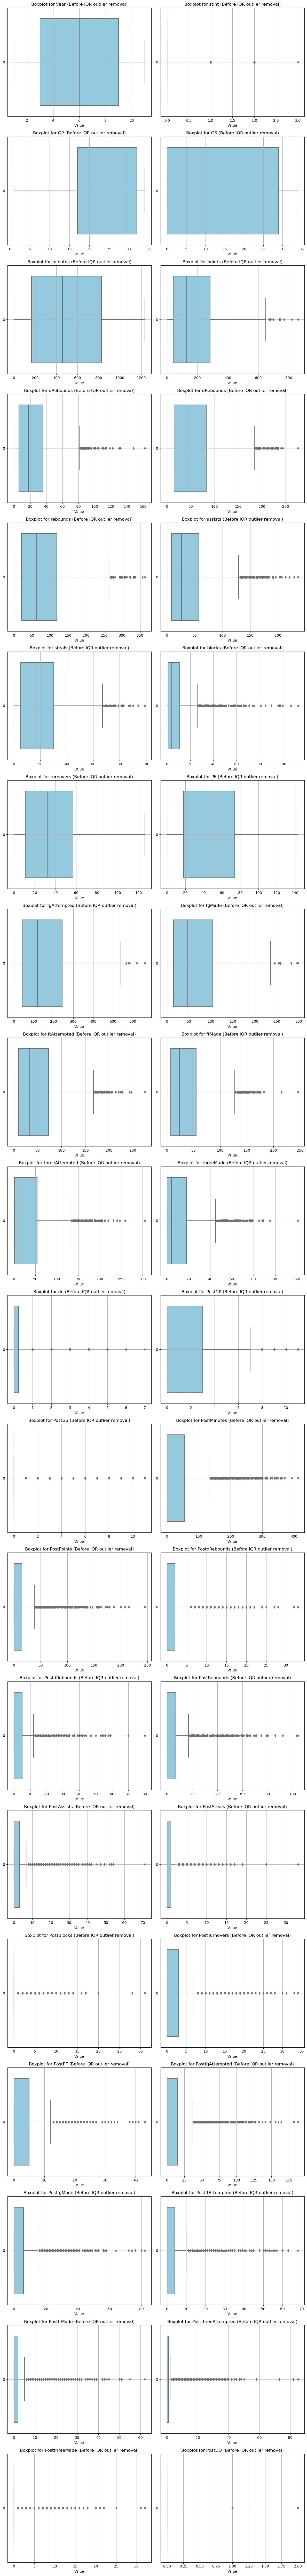

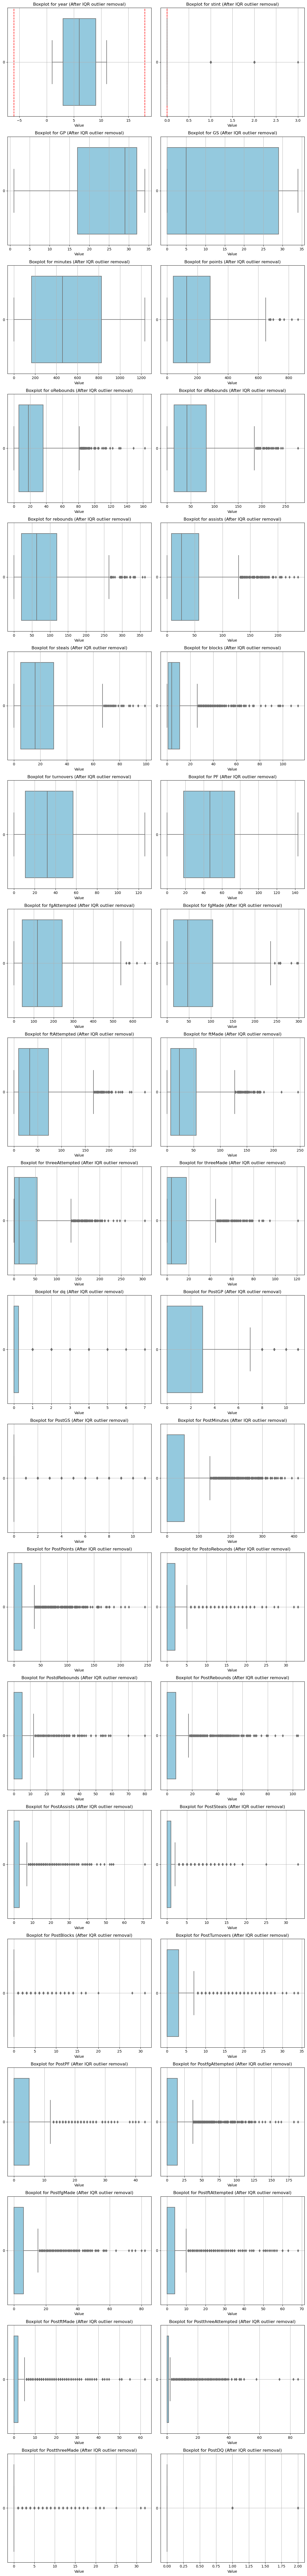

Number of rows deleted due to IQR outliers: 141


In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import iqr

# Select numerical columns
numerical_cols = player_teams.select_dtypes(['number'])

# Initialize dictionaries for IQR and outlier detection
iqr_values = {}
lower_bounds = {}
upper_bounds = {}
outliers_iqr = pd.DataFrame(False, index=player_teams.index, columns=numerical_cols.columns)

# Plot before IQR changes
num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 5))
axes = axes.flatten()

for i, column in enumerate(numerical_cols.columns):
    sns.boxplot(data=player_teams[column], ax=axes[i], color='skyblue', orient='h')
    axes[i].set_title(f'Boxplot for {column} (Before IQR outlier removal)')
    axes[i].set_xlabel('Value')
    axes[i].grid(True)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# Calculate IQR and detect outliers
for column in numerical_cols.columns:
    Q1 = player_teams[column].quantile(0.25)  # 25th percentile
    Q3 = player_teams[column].quantile(0.75)  # 75th percentile
    column_iqr = iqr(player_teams[column])  # IQR calculation
    iqr_values[column] = column_iqr
    
    # Calculate lower and upper bounds for outliers
    lower_bound = Q1 - 1.5 * column_iqr
    upper_bound = Q3 + 1.5 * column_iqr
    lower_bounds[column] = lower_bound
    upper_bounds[column] = upper_bound
    
    # Identify outliers
    outliers_iqr[column] = (player_teams[column] < lower_bound) | (player_teams[column] > upper_bound)

# Plot boxplots after IQR-based outlier detection
num_rows_after = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows_after, num_columns, figsize=(12, num_rows_after * 5))
axes = axes.flatten()

for i, column in enumerate(numerical_cols.columns):
    sns.boxplot(data=player_teams[column], ax=axes[i], color='skyblue', orient='h')
    
    # Add red dotted lines for IQR bounds
    Q1 = player_teams[column].quantile(0.25)
    Q3 = player_teams[column].quantile(0.75)
    lower_bound = lower_bounds[column]
    upper_bound = upper_bounds[column]
    
    axes[i].axvline(x=lower_bound, color='red', linestyle='--')
    axes[i].axvline(x=upper_bound, color='red', linestyle='--')
    
    axes[i].set_title(f'Boxplot for {column} (After IQR outlier removal)')
    axes[i].set_xlabel('Value')
    axes[i].grid(True)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# Remove rows that contain outliers
rows_with_outliers = outliers_iqr.any(axis=1)
player_teams_no_outliers = player_teams[~rows_with_outliers]  # Filter out rows with outliers

# Identify number of rows deleted
num_rows_deleted = player_teams.shape[0] - player_teams_no_outliers.shape[0]
print(f"Number of rows deleted due to IQR outliers: {num_rows_deleted}")


# Implementing PER (Player Efficiency Rating (per minute))

#### Due to the amount to data present in this dataset we find it a good idea to reduce it to give the players a rating for the season they just played

In [10]:
"""# VPS Player Value Calculator

# https://www.hudl.com/blog/value-point-system-the-all-in-one-stat-that-keeps-growing

player_teams['FT_Missed'] = player_teams['ftAttempted'] - player_teams['ftMade']
player_teams['FG_Missed'] = player_teams['fgAttempted'] - player_teams['fgMade']

player_teams['VPS'] = (player_teams['points'] + player_teams['rebounds'] + 2 * (player_teams['assists'] + player_teams['steals'] + player_teams['blocks'])) / (
    player_teams['FT_Missed'] + 2 * (player_teams['PF'] + player_teams['turnovers'] + player_teams['FG_Missed']) + 1
)
player_teams['VPS_Per_Minute'] = player_teams['VPS'] / (player_teams['minutes'] + 1) 

# For display purposes, select only relevant columns
player_teams_vps = player_teams[['playerID', 'year', 'tmID', 'VPS', 'VPS_Per_Minute']]


display(player_teams_vps)

player_teams_vps.to_csv('cleaned_datasets/players_teams_cleaned.csv', index=False)"""


# Resorting to EFF
# https://en.wikipedia.org/wiki/Efficiency_(basketball) / https://www.sportsbettingdime.com/guides/how-to/calculate-per/

player_teams['FT_Missed'] = player_teams['ftAttempted'] - player_teams['ftMade']
player_teams['FG_Missed'] = player_teams['fgAttempted'] - player_teams['fgMade']
player_teams['Performance_Per_Game'] = (player_teams['points'] + player_teams['rebounds'] + player_teams['assists'] + player_teams['steals'] + player_teams['blocks'] -player_teams['FG_Missed'] - player_teams['FT_Missed'] - player_teams['turnovers']) / (player_teams['GP'] + 1e-6)  

player_teams_performance = player_teams[['playerID', 'year', 'tmID', 'Performance_Per_Game']]



"""
player_teams_year_1 = player_teams_performance[player_teams_performance['year'] == 1]
# Confirmar se bate com o MVP do ano or close to it
highest_performance_year_1 = player_teams_year_1.loc[player_teams_year_1['Performance_Per_Game'].idxmax()]
print("Highest Performance Per Game in Year 1:")
print(highest_performance_year_1)
"""




'\nplayer_teams_year_1 = player_teams_performance[player_teams_performance[\'year\'] == 1]\n# Confirmar se bate com o MVP do ano or close to it\nhighest_performance_year_1 = player_teams_year_1.loc[player_teams_year_1[\'Performance_Per_Game\'].idxmax()]\nprint("Highest Performance Per Game in Year 1:")\nprint(highest_performance_year_1)\n'

# Create Clean CSV

In [11]:
player_teams_performance.to_csv('../cleaned_datasets/players_teams_cleaned.csv', index=False)